# Evaluation: which backbone works best for independent crop + disease CNNs?

**Setup in one line:** for each backbone, one CNN predicts the **crop** (55 classes) and a separate CNN predicts
the **disease** (175 classes). A composition (crop + disease pair, 333 candidates) is scored as
log p(crop) + log p(disease). **Seen test** = 2000 images of pairs that appear in training;
**unseen test** = 1448 images of 10 pairs that never appear in training.

**How to read this notebook**

| Section | Question it answers |
|---|---|
| 1 | Were all backbones trained the same way? |
| 2 | **Which backbone wins?** (scoreboard, verdict with confidence intervals) |
| 3 | Does the ranking change if we allow 5 guesses instead of 1? |
| 4 | How much does training help over the untouched ImageNet weights? |
| 5 | What does each backbone cost (size, training time, speed)? |
| 6-12 | Why the models behave as they do (per-model detail, errors, unseen pairs, class imbalance) |

Every fine-tuned result is the **mean over the training seeds** found in `runs/main` (each seed = its own crop
model + disease model, always paired within the seed). Everything is computed from the saved results in `runs/`;
nothing is retrained. Re-run all cells after new runs.

In [1]:
import json, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from IPython.display import display, Markdown
from PIL import Image
from common import read_csv, candidate_comps, comp_scores

METHOD_DIRS = {"fine-tuned": Path("runs/main"), "frozen": Path("runs/frozen")}  # frozen = linear_probe.py --save_runs
IMG_DIR = Path("DPD_Small_Dataset")
BACKBONES = ["efficientnet_b0", "resnet50", "convnext_tiny", "efficientnet_b3"]  # fixed order = fixed colours
NAME = {"efficientnet_b0": "EfficientNet-B0", "resnet50": "ResNet-50",
        "convnext_tiny": "ConvNeXt-Tiny", "efficientnet_b3": "EfficientNet-B3"}
WEIGHTS = {"efficientnet_b0": "ImageNet-1K V1", "resnet50": "ImageNet-1K V2",
           "convnext_tiny": "ImageNet-1K V1", "efficientnet_b3": "ImageNet-1K V1"}  # torchvision weights="DEFAULT"
COLOR = dict(zip(BACKBONES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUES = LinearSegmentedColormap.from_list("blues", ["#f0efec", "#9ec5f4", "#3987e5", "#1c5cab", "#0d366b"])
METRICS = ["seen_top1", "unseen_top1", "harmonic_top1", "seen_top5", "unseen_top5", "harmonic_top5"]
LABEL = {"seen_top1": "Seen Top-1", "unseen_top1": "Unseen Top-1", "harmonic_top1": "Harmonic Top-1",
         "seen_top5": "Seen Top-5", "unseen_top5": "Unseen Top-5", "harmonic_top5": "Harmonic Top-5"}
FT = "fine-tuned"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": AXIS,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False, "lines.linewidth": 2,
})

tr, se, un = (read_csv(f"DPD_Small_{s}.csv") for s in ("train", "test_seen", "test_unseen"))
comp_ids, crop_idx, dis_idx = candidate_comps(tr, se, un)
comp_name = pd.concat([tr, se, un]).drop_duplicates("comp").set_index("comp")["comp_name"]
dis_name = pd.concat([tr, se, un]).drop_duplicates("disease").set_index("disease")["disease_name"]


def bar_labels(ax, bars, fmt="{:.3f}", size=8):
    for b in bars:
        ax.annotate(fmt.format(b.get_height()), (b.get_x() + b.get_width() / 2, b.get_height()),
                    xytext=(0, 2), textcoords="offset points", ha="center", va="bottom", fontsize=size, color=INK2)


def grouped_bars(ax, groups, values, backbones, ylim=(0, 1.08), errs=None):
    'values[bb] = list aligned with groups; one bar per backbone inside each group; errs[bb] = optional error bars.'
    w = 0.8 / len(backbones); x = np.arange(len(groups))
    for i, bb in enumerate(backbones):
        bars = ax.bar(x + (i - (len(backbones) - 1) / 2) * w, values[bb], w,
                      color=COLOR[bb], edgecolor=SURFACE, linewidth=2, label=NAME[bb],
                      yerr=None if errs is None else errs[bb], capsize=2, error_kw={"ecolor": INK2, "elinewidth": 1})
        bar_labels(ax, bars)
    ax.set_xticks(x, groups); ax.set_ylim(*ylim); ax.tick_params(axis="x", colors=INK2)


def top_legend(fig, ax, ncol=4, top=0.92):
    fig.tight_layout(rect=(0, 0, 1, top))
    fig.legend(*ax.get_legend_handles_labels(), loc="upper center", ncol=ncol)

In [2]:
rows = []
for method, d in METHOD_DIRS.items():
    for f in sorted(d.glob("*/results.json")):
        r = json.loads(f.read_text()); a = r["args"]
        h = pd.DataFrame(r.get("history", []))
        rows.append({"method": method, "backbone": a["backbone"], "task": a["task"], "seed": a.get("seed", 0),
                     "val_top1": r["best_val_top1"],
                     "seen_top1": r["seen_top1"], "seen_top5": r["seen_top5"],
                     "unseen_top1": r["unseen_top1"], "unseen_top5": r["unseen_top5"],
                     "params_M": r.get("params_M"), "img_size": r.get("img_size"), "peak_gpu_GB": r.get("peak_gpu_GB"),
                     "sec_per_epoch": h["sec"].mean() if "sec" in h else np.nan,
                     "train_min": h["sec"].sum() / 60 if "sec" in h else np.nan,
                     "args": a, "history": h, "dir": f.parent})
runs = pd.DataFrame(rows)
assert len(runs), "no finished runs found"

# one run per (method, backbone, task, seed); if one was trained more than once, keep the best validation score
RUN = (runs.sort_values("val_top1", ascending=False)
           .drop_duplicates(["method", "backbone", "task", "seed"]).set_index(["method", "backbone", "task", "seed"]))
# seeds that have BOTH a crop and a disease run: a composition always pairs crop + disease from the same seed
SEEDS = {}
for (m, b), g in runs.groupby(["method", "backbone"]):
    s = sorted(set(g.loc[g["task"] == "crop", "seed"]) & set(g.loc[g["task"] == "disease", "seed"]))
    if s:
        SEEDS[m, b] = s
present = [b for b in BACKBONES if (FT, b) in SEEDS]
frozen_present = [b for b in BACKBONES if ("frozen", b) in SEEDS]
task_vals = lambda m, b, t, col: np.array([RUN.loc[(m, b, t, s), col] for s in SEEDS[m, b]], dtype=float)  # one per seed
tmean = lambda m, b, t, col: float(task_vals(m, b, t, col).mean())
tsd = lambda m, b, t, col: float(task_vals(m, b, t, col).std(ddof=1)) if len(SEEDS[m, b]) > 1 else 0.0
print("fine-tuned backbones (seeds):", {NAME[b]: SEEDS[FT, b] for b in present})
print("frozen baselines:            ", [NAME[b] for b in frozen_present] or "none (run linear_probe.py --save_runs runs/frozen)")

# backbone used for the single-model analyses at the end: best mean validation Top-1 (never chosen on test data)
BEST = max(present, key=lambda b: tmean(FT, b, "crop", "val_top1") + tmean(FT, b, "disease", "val_top1"))
print("single-model analyses use:", NAME[BEST])

fine-tuned backbones (seeds): {'ResNet-50': [42, 123, 2026], 'ConvNeXt-Tiny': [42, 123, 2026], 'EfficientNet-B3': [42, 123, 2026]}
frozen baselines:             ['EfficientNet-B0', 'ResNet-50', 'ConvNeXt-Tiny', 'EfficientNet-B3']
single-model analyses use: ConvNeXt-Tiny


## 1. Were all backbones trained the same way?

Every backbone starts from torchvision's ImageNet-1K weights and is then **fine-tuned**: all layers are trained on
our images (the ImageNet weights are only the starting point). **No hyperparameters were tuned**: every run uses
the same `train.py` defaults. The table below is read from each run's saved settings, so it shows what was
actually used.
Each backbone is trained once per seed; only the seed changes between runs (the train/validation split is fixed).

In [3]:
SETTINGS = ["epochs", "lr", "wd", "bs", "label_smooth", "aug", "freeze_epochs"]
cfg = lambda b, t, s: {k: RUN.loc[(FT, b, t, s), "args"][k] for k in SETTINGS}
first = lambda b: SEEDS[FT, b][0]
setup = pd.DataFrame({NAME[b]: {"pretrained weights": WEIGHTS[b],
                                "image size": int(RUN.loc[(FT, b, "crop", first(b)), "img_size"]),
                                **cfg(b, "crop", first(b)),
                                "seeds": ", ".join(str(s) for s in SEEDS[FT, b])} for b in present}).T
display(setup)

same_runs = all(cfg(b, t, s) == cfg(b, "crop", first(b)) for b in present for t in ("crop", "disease") for s in SEEDS[FT, b])
differs = [c for c in setup.columns if setup[c].nunique() > 1]
print("every crop and disease run of a backbone (all seeds) uses identical settings:", same_runs)
print("settings that differ between backbones:", differs or "none")
print("(image size: each backbone uses its native ImageNet resolution, 300px for EfficientNet-B3, 224px otherwise)")

,pretrained weights,image size,epochs,lr,wd,bs,label_smooth,aug,freeze_epochs,seeds
ResNet-50,ImageNet-1K V2,224,15,0.0003,0.0001,32,0.1,strong,0,"42, 123, 2026"
ConvNeXt-Tiny,ImageNet-1K V1,224,15,0.0003,0.0001,32,0.1,strong,0,"42, 123, 2026"
EfficientNet-B3,ImageNet-1K V1,300,15,0.0003,0.0001,32,0.1,strong,0,"42, 123, 2026"


every crop and disease run of a backbone (all seeds) uses identical settings: True
settings that differ between backbones: ['pretrained weights', 'image size']
(image size: each backbone uses its native ImageNet resolution, 300px for EfficientNet-B3, 224px otherwise)


## 2. Scoreboard: which backbone wins?

Composition accuracy for each fine-tuned backbone, **averaged over the training seeds** (each seed pairs its own
crop and disease model). **Harmonic** = harmonic mean of seen and unseen accuracy, the project's headline metric:
it is only high if a model does well on *both*. It is computed per seed, then averaged.

Each value is **mean ± SD across seeds**, then a **95% confidence interval** from a paired bootstrap of the
seed-averaged metric (the test images are resampled 2000 times, the same resample for every backbone and seed).
The SD shows how much a result depends on the training seed; the interval shows how much it depends on which test
images happened to be drawn. If the interval of two backbones' gap includes zero, they are reported as **tied**.

In [4]:
pos = {c: i for i, c in enumerate(comp_ids)}
S, R = {}, {}   # S = composition scores; R = rank of the true composition (0 = top guess); both keyed by seed
for method, bbs in [(FT, present), ("frozen", frozen_present)]:
    for bb in bbs:
        for sd in SEEDS[method, bb]:
            for split, df in [("seen", se), ("unseen", un)]:
                s = comp_scores(np.load(RUN.loc[(method, bb, "crop", sd), "dir"] / f"probs_{split}.npy"),
                                np.load(RUN.loc[(method, bb, "disease", sd), "dir"] / f"probs_{split}.npy"),
                                crop_idx, dis_idx)
                y = np.array([pos[c] for c in df["comp"]])
                R[method, bb, sd, split] = (s > s[np.arange(len(y)), y][:, None]).sum(1)
                if method == FT:
                    S[bb, sd, split] = s

B = 2000
rng = np.random.default_rng(0)
IDX = {"seen": rng.integers(0, len(se), (B, len(se))), "unseen": rng.integers(0, len(un), (B, len(un)))}
hm = lambda s, u: np.where(s + u > 0, 2 * s * u / np.maximum(s + u, 1e-12), 0.0)

per_seed, point, SD, boot = {}, {}, {}, {}
for key in [(FT, b) for b in present] + [("frozen", b) for b in frozen_present]:
    ps, bss = [], []
    for sd in SEEDS[key]:
        p, bs = {}, {}
        for k in (1, 5):
            for split in ("seen", "unseen"):
                hit = R[(*key, sd, split)] < k
                p[f"{split}_top{k}"], bs[f"{split}_top{k}"] = hit.mean(), hit[IDX[split]].mean(1)
            p[f"harmonic_top{k}"] = float(hm(p[f"seen_top{k}"], p[f"unseen_top{k}"]))
            bs[f"harmonic_top{k}"] = hm(bs[f"seen_top{k}"], bs[f"unseen_top{k}"])
        ps.append(p); bss.append(bs)
    per_seed[key] = pd.DataFrame(ps, index=pd.Index(SEEDS[key], name="seed"))[METRICS]
    point[key] = per_seed[key].mean().to_dict()
    SD[key] = per_seed[key].std(ddof=1).to_dict()                        # NaN when there is only one seed
    boot[key] = {m: np.mean([bs[m] for bs in bss], 0) for m in METRICS}  # bootstrap of the seed-averaged metric

ci = lambda key, m: np.percentile(boot[key][m], [2.5, 97.5])
fmt = lambda key, m: (f"{point[key][m]:.3f}" + ("" if np.isnan(SD[key][m]) else f" ± {SD[key][m]:.3f}")
                      + "  [{:.3f}, {:.3f}]".format(*ci(key, m)))
lb = pd.DataFrame({LABEL[m]: {NAME[b]: point[FT, b][m] for b in present} for m in METRICS})
txt = pd.DataFrame({LABEL[m]: {NAME[b]: fmt((FT, b), m) for b in present} for m in METRICS})
bold = lambda col: ["font-weight: bold; background-color: #cde2fb" if v == lb[col.name].max() else "" for v in lb[col.name]]
display(Markdown("**Composition accuracy, fine-tuned: mean ± SD over seeds [95% CI]; best mean per column highlighted**"))
display(txt.style.apply(bold))
display(Markdown("**Each seed on its own**"))
display(pd.concat({NAME[b]: per_seed[FT, b] for b in present}, names=["backbone"]).rename(columns=LABEL).round(3))

**Composition accuracy, fine-tuned: mean ± SD over seeds [95% CI]; best mean per column highlighted**

,Seen Top-1,Unseen Top-1,Harmonic Top-1,Seen Top-5,Unseen Top-5,Harmonic Top-5
ResNet-50,"0.685 ± 0.005 [0.666, 0.703]","0.070 ± 0.008 [0.059, 0.081]","0.127 ± 0.014 [0.109, 0.145]","0.891 ± 0.000 [0.878, 0.903]","0.349 ± 0.031 [0.327, 0.369]","0.500 ± 0.032 [0.478, 0.522]"
ConvNeXt-Tiny,"0.705 ± 0.005 [0.686, 0.722]","0.073 ± 0.005 [0.062, 0.085]","0.132 ± 0.008 [0.114, 0.151]","0.890 ± 0.004 [0.878, 0.903]","0.363 ± 0.029 [0.342, 0.385]","0.516 ± 0.030 [0.493, 0.537]"
EfficientNet-B3,"0.693 ± 0.003 [0.675, 0.710]","0.078 ± 0.009 [0.067, 0.090]","0.140 ± 0.014 [0.121, 0.159]","0.900 ± 0.004 [0.887, 0.911]","0.426 ± 0.023 [0.403, 0.448]","0.578 ± 0.022 [0.556, 0.598]"


**Each seed on its own**

Seen Top-1  Unseen Top-1  Harmonic Top-1  Seen Top-5  \
backbone        seed                                                         
ResNet-50       42         0.690         0.079           0.142       0.890   
                123        0.686         0.063           0.115       0.891   
                2026       0.680         0.068           0.124       0.890   
ConvNeXt-Tiny   42         0.708         0.077           0.138       0.890   
                123        0.707         0.067           0.122       0.894   
                2026       0.699         0.075           0.135       0.886   
EfficientNet-B3 42         0.697         0.071           0.129       0.904   
                123        0.692         0.088           0.156       0.898   
                2026       0.692         0.075           0.135       0.897   

                      Unseen Top-5  Harmonic Top-5  
backbone        seed                                
ResNet-50       42           0.360           0.513  
                123          0.372           0.524  
                2026         0.314           0.464  
ConvNeXt-Tiny   42           0.383           0.536  
                123          0.376           0.530  
                2026         0.330           0.481  
EfficientNet-B3 42           0.450           0.601  
                123          0.423           0.575  
                2026         0.405           0.558

### Verdict

For each metric: the leader (highest mean over seeds), and every backbone that is statistically tied with it (the
95% CI of the paired difference of seed means includes zero). The last column checks seed variation directly: does
the leader's *worst* seed still beat the other backbone's *best* seed? "Win probability" is the share of bootstrap
resamples in which each backbone's seed-averaged score comes first.

In [5]:
sep = lambda m, a, b: per_seed[FT, a][m].min() > per_seed[FT, b][m].max()
lines = ["| Metric | Leader | Tied with leader | Not tied (clearly behind) | Leader's worst seed > their best seed |",
         "|---|---|---|---|---|"]
for m in METRICS:
    vals = {b: point[FT, b][m] for b in present}
    lead = max(vals, key=vals.get)
    tied = [b for b in present if b != lead and np.percentile(boot[FT, lead][m] - boot[FT, b][m], 2.5) <= 0]
    behind = [b for b in present if b not in tied and b != lead]
    seps = ", ".join(f"{NAME[b]}: {'yes' if sep(m, lead, b) else 'no'}" for b in present if b != lead) or "-"
    lines.append(f"| {LABEL[m]} | **{NAME[lead]}** ({vals[lead]:.3f}) | {', '.join(NAME[t] for t in tied) or '-'} "
                 f"| {', '.join(NAME[t] for t in behind) or '-'} | {seps} |")
display(Markdown("\n".join(lines)))

win = pd.DataFrame({LABEL[m]: np.bincount(np.stack([boot[FT, b][m] for b in present]).argmax(0),
                                          minlength=len(present)) / B for m in METRICS},
                   index=[NAME[b] for b in present])
display(Markdown("**Win probability (share of bootstrap resamples where the backbone is first)**"))
display(win.style.format("{:.0%}").background_gradient(cmap=BLUES, vmin=0, vmax=1))

| Metric | Leader | Tied with leader | Not tied (clearly behind) | Leader's worst seed > their best seed |
|---|---|---|---|---|
| Seen Top-1 | **ConvNeXt-Tiny** (0.705) | - | ResNet-50, EfficientNet-B3 | ResNet-50: yes, EfficientNet-B3: yes |
| Unseen Top-1 | **EfficientNet-B3** (0.078) | ResNet-50, ConvNeXt-Tiny | - | ResNet-50: no, ConvNeXt-Tiny: no |
| Harmonic Top-1 | **EfficientNet-B3** (0.140) | ResNet-50, ConvNeXt-Tiny | - | ResNet-50: no, ConvNeXt-Tiny: no |
| Seen Top-5 | **EfficientNet-B3** (0.900) | - | ResNet-50, ConvNeXt-Tiny | ResNet-50: yes, ConvNeXt-Tiny: yes |
| Unseen Top-5 | **EfficientNet-B3** (0.426) | - | ResNet-50, ConvNeXt-Tiny | ResNet-50: yes, ConvNeXt-Tiny: yes |
| Harmonic Top-5 | **EfficientNet-B3** (0.578) | - | ResNet-50, ConvNeXt-Tiny | ResNet-50: yes, ConvNeXt-Tiny: yes |

**Win probability (share of bootstrap resamples where the backbone is first)**

,Seen Top-1,Unseen Top-1,Harmonic Top-1,Seen Top-5,Unseen Top-5,Harmonic Top-5
ResNet-50,0%,3%,3%,0%,0%,0%
ConvNeXt-Tiny,99%,15%,15%,0%,0%,0%
EfficientNet-B3,1%,83%,82%,100%,100%,100%


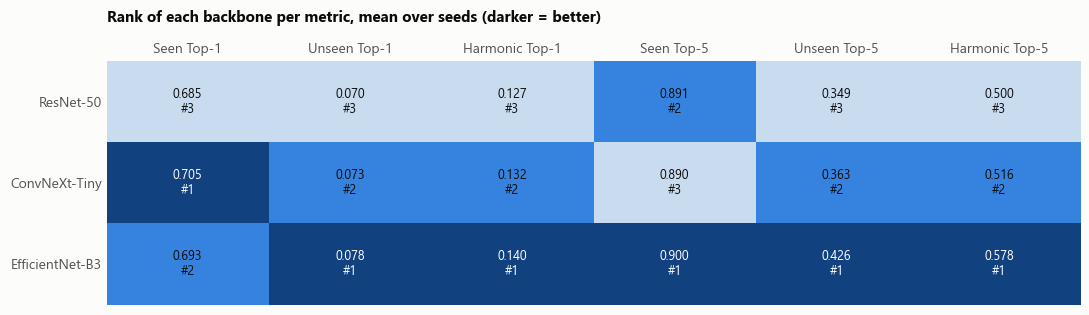

In [6]:
# rank grid: every metric at a glance (1 = best). Colour = rank, text = value.
vals = lb.values
ranks = (-vals).argsort(0).argsort(0) + 1
n = len(present)
fig, ax = plt.subplots(figsize=(11, 0.55 * n + 1.6))
ax.imshow((n - ranks) / max(n - 1, 1), cmap=BLUES, vmin=-0.15, vmax=1.1, aspect="auto")
for (r, c), v in np.ndenumerate(vals):
    ax.text(c, r, f"{v:.3f}\n#{ranks[r, c]}", ha="center", va="center", fontsize=9,
            color="white" if ranks[r, c] <= max(1, n // 2) else INK)
ax.set_xticks(range(len(METRICS)), [LABEL[m] for m in METRICS]); ax.set_yticks(range(n), lb.index)
ax.tick_params(colors=INK2, length=0); ax.grid(False); ax.xaxis.tick_top()
for s in ax.spines.values(): s.set_visible(False)
ax.set_title("Rank of each backbone per metric, mean over seeds (darker = better)", pad=28)
fig.tight_layout(); plt.show()

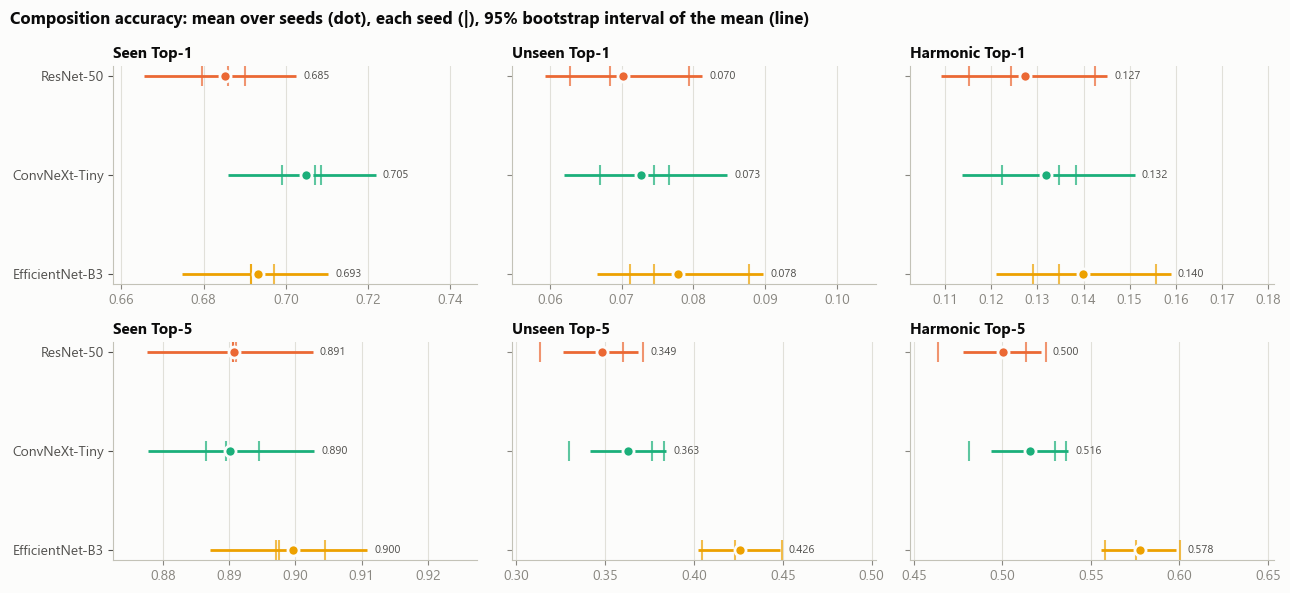

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(13, 0.5 * len(present) * 2 + 3), sharey=True)
for ax, m in zip(axes.flat, METRICS):
    for i, b in enumerate(present):
        lo, hi = ci((FT, b), m)
        ax.hlines(i, lo, hi, color=COLOR[b], linewidth=2)
        ax.plot(per_seed[FT, b][m].values, [i] * len(SEEDS[FT, b]), "|", color=COLOR[b], markersize=14,
                markeredgewidth=1.5, alpha=0.7)
        ax.plot(point[FT, b][m], i, "o", color=COLOR[b], markersize=8, markeredgecolor=SURFACE, markeredgewidth=2)
        ax.annotate(f"{point[FT, b][m]:.3f}", (max(hi, per_seed[FT, b][m].max()), i), xytext=(5, 0),
                    textcoords="offset points", va="center", fontsize=8, color=INK2)
    ax.set_title(LABEL[m]); ax.grid(True, axis="x"); ax.grid(False, axis="y")
    lo_all = min(min(ci((FT, b), m)[0], per_seed[FT, b][m].min()) for b in present)
    hi_all = max(max(ci((FT, b), m)[1], per_seed[FT, b][m].max()) for b in present)
    pad = (hi_all - lo_all) * 0.35 + 0.005
    ax.set_xlim(lo_all - pad * 0.3, hi_all + pad)
axes[0, 0].set_yticks(range(len(present)), [NAME[b] for b in present]); axes[0, 0].invert_yaxis()
for ax in axes[:, 0]:
    ax.tick_params(axis="y", colors=INK2)
fig.suptitle("Composition accuracy: mean over seeds (dot), each seed (|), 95% bootstrap interval of the mean (line)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); plt.show()

## 3. Accuracy as more guesses are allowed (Top-k)

Fraction of test images whose true composition is among the backbone's top *k* guesses. If the lines cross,
the "best" backbone depends on how many guesses the application can show. Lines are the mean over seeds; the band is the range across seeds.

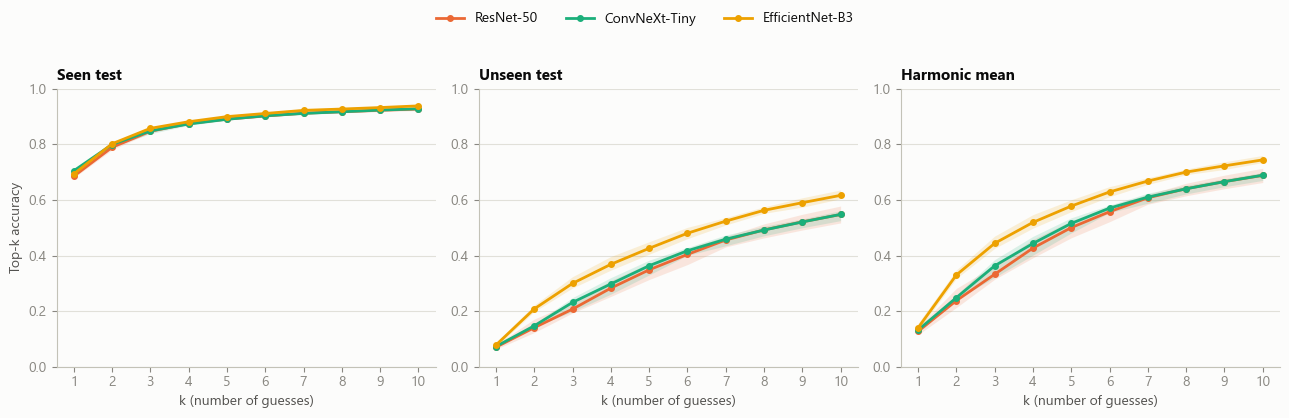

In [8]:
K = np.arange(1, 11)
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for b in present:
    curves = []
    for sd in SEEDS[FT, b]:
        s_k = np.array([(R[FT, b, sd, "seen"] < k).mean() for k in K])
        u_k = np.array([(R[FT, b, sd, "unseen"] < k).mean() for k in K])
        curves.append([s_k, u_k, hm(s_k, u_k)])
    curves = np.array(curves)  # seeds x (seen, unseen, harmonic) x K
    for j, ax in enumerate(axes):
        ax.plot(K, curves[:, j].mean(0), color=COLOR[b], marker="o", markersize=4, label=NAME[b])
        ax.fill_between(K, curves[:, j].min(0), curves[:, j].max(0), color=COLOR[b], alpha=0.15, linewidth=0)
for ax, t in zip(axes, ["Seen test", "Unseen test", "Harmonic mean"]):
    ax.set_title(t); ax.set_xlabel("k (number of guesses)"); ax.set_xticks(K); ax.set_ylim(0, 1)
axes[0].set_ylabel("Top-k accuracy")
top_legend(fig, axes[0], top=0.88); plt.show()

## 4. Untouched ImageNet weights vs fine-tuning

**Frozen** = the ImageNet weights exactly as downloaded, with only a linear classifier trained on top
(`linear_probe.py --save_runs runs/frozen`). **Fine-tuned** = all layers trained on our images (`train.py`).
This shows how much of each backbone's result comes from its pretrained features and how much from training.
The frozen baseline is run once (a linear head on fixed features); fine-tuned values are means over seeds.

Seen Top-1            Unseen Top-1            Harmonic Top-1  \
                    frozen fine-tuned       frozen fine-tuned         frozen   
ResNet-50            0.522      0.685        0.035      0.070          0.066   
ConvNeXt-Tiny        0.592      0.705        0.064      0.073          0.115   
EfficientNet-B3      0.574      0.693        0.048      0.078          0.088   

                           Harmonic Top-5             
                fine-tuned         frozen fine-tuned  
ResNet-50            0.127          0.356      0.500  
ConvNeXt-Tiny        0.132          0.442      0.516  
EfficientNet-B3      0.140          0.420      0.578

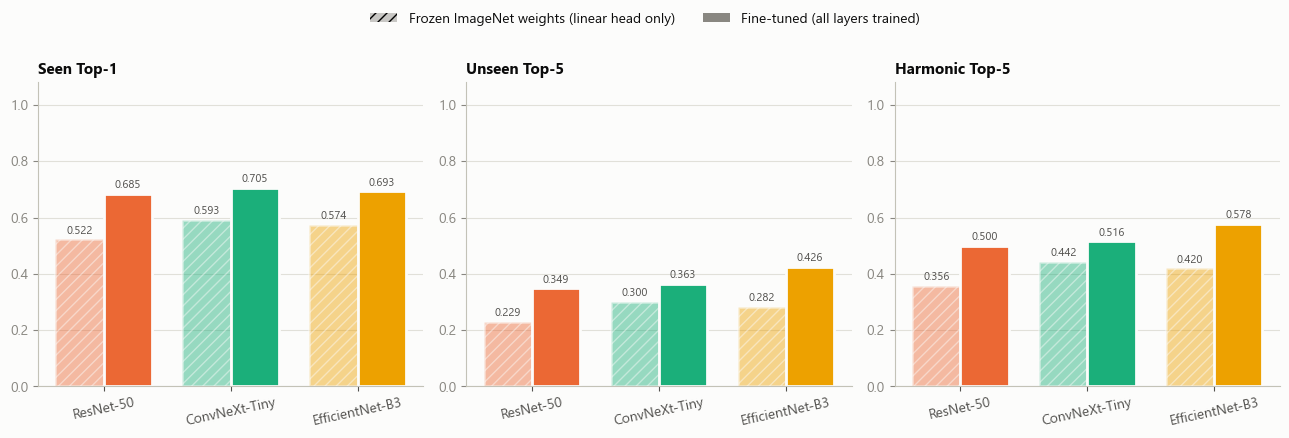

**Independent model seen-test Top-1, frozen vs fine-tuned**

crop            disease           
                frozen fine-tuned  frozen fine-tuned
ResNet-50        0.823      0.902   0.540      0.695
ConvNeXt-Tiny    0.878      0.904   0.597      0.713
EfficientNet-B3  0.856      0.909   0.588      0.702

In [9]:
if not frozen_present:
    print("No frozen runs found. Run: python linear_probe.py --img_dir DPD_Small_Dataset "
          "--models efficientnet_b0 resnet50 convnext_tiny efficientnet_b3 --save_runs runs/frozen")
else:
    both = [b for b in present if b in frozen_present]
    tbl = pd.DataFrame({(LABEL[m], meth): {NAME[b]: point[(meth, b)][m] for b in both}
                        for m in ["seen_top1", "unseen_top1", "harmonic_top1", "harmonic_top5"]
                        for meth in ("frozen", FT)})
    display(tbl.round(3))

    show = ["seen_top1", "unseen_top5", "harmonic_top5"]
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
    w = 0.38
    for ax, m in zip(axes, show):
        x = np.arange(len(both))
        for j, (meth, kw) in enumerate([("frozen", dict(alpha=0.45, hatch="///")), (FT, {})]):
            bars = ax.bar(x + (j - 0.5) * w, [point[(meth, b)][m] for b in both], w,
                          color=[COLOR[b] for b in both], edgecolor=SURFACE, linewidth=2, **kw)
            bar_labels(ax, bars)
        ax.set_xticks(x, [NAME[b] for b in both], rotation=12); ax.tick_params(axis="x", colors=INK2)
        ax.set_ylim(0, 1.08); ax.set_title(LABEL[m])
    fig.tight_layout(rect=(0, 0, 1, 0.9))
    fig.legend(handles=[Patch(facecolor=MUTED, alpha=0.45, hatch="///", label="Frozen ImageNet weights (linear head only)"),
                        Patch(facecolor=MUTED, label="Fine-tuned (all layers trained)")], loc="upper center", ncol=2)
    plt.show()

    task_tbl = pd.DataFrame({(task, meth): {NAME[b]: tmean(meth, b, task, "seen_top1") for b in both}
                             for task in ("crop", "disease") for meth in ("frozen", FT)})
    display(Markdown("**Independent model seen-test Top-1, frozen vs fine-tuned**"))
    display(task_tbl.round(3))

## 5. Cost: size, training time and speed

Parameters are per model (each backbone needs two: crop + disease). Training times are means over seeds, measured on
this laptop (RTX 4050, 6 GB); they are stable from epoch to epoch. EfficientNet-B3 is slower partly because of its
300 px input, but at batch size 32 it also needs about 5.3 GB of GPU memory, close to the card's limit: in the
per-run table below one of its runs trained at ~96 s/epoch while the others took ~190-235 s/epoch, which fits the
driver spilling into (much slower) shared system memory. Its training time here is therefore partly a property of
this GPU. Inference speed is measured live on this machine when a GPU is available.

In [10]:
MEASURE_SPEED = True   # set False to skip (takes ~30 s on a GPU)
speed = {}
if MEASURE_SPEED:
    import torch
    from torchvision import models
    from train import DEFAULT_SIZE
    if torch.cuda.is_available():
        for b in present:
            m = getattr(models, b)(weights=None).cuda().eval()
            x = torch.randn(64, 3, DEFAULT_SIZE.get(b, 224), DEFAULT_SIZE.get(b, 224), device="cuda")
            with torch.no_grad(), torch.autocast("cuda"):
                for _ in range(5): m(x)
                torch.cuda.synchronize(); t0 = time.time()
                for _ in range(20): m(x)
                torch.cuda.synchronize()
            speed[b] = 64 * 20 / (time.time() - t0)
            del m, x; torch.cuda.empty_cache()
    else:
        print("no GPU: speed test skipped")

cost = pd.DataFrame({NAME[b]: {
    "params per model (M)": RUN.loc[(FT, b, "crop", SEEDS[FT, b][0]), "params_M"],
    "image size": int(RUN.loc[(FT, b, "crop", SEEDS[FT, b][0]), "img_size"]),
    "peak GPU memory (GB)": pd.Series(np.r_[task_vals(FT, b, "crop", "peak_gpu_GB"),
                                            task_vals(FT, b, "disease", "peak_gpu_GB")]).max(),
    "s / epoch (crop)": tmean(FT, b, "crop", "sec_per_epoch"),
    "s / epoch (disease)": tmean(FT, b, "disease", "sec_per_epoch"),
    "train time, both models (min)": tmean(FT, b, "crop", "train_min") + tmean(FT, b, "disease", "train_min"),
    "inference img/s (one model)": speed.get(b, np.nan),
    "Harmonic Top-1": point[FT, b]["harmonic_top1"], "Harmonic Top-5": point[FT, b]["harmonic_top5"]}
    for b in present}).T
display(cost.astype(float).round(3))

ft_runs = RUN.loc[FT].reset_index()
display(Markdown("**Seconds per epoch, each run**"))
display(ft_runs[ft_runs["backbone"].isin(present)]
        .pivot_table(index=["backbone", "task"], columns="seed", values="sec_per_epoch").round(0))

,params per model (M),image size,peak GPU memory (GB),s / epoch (crop),s / epoch (disease),"train time, both models (min)",inference img/s (one model),Harmonic Top-1,Harmonic Top-5
ResNet-50,23.6,224.0,1.81,68.156,66.533,33.672,496.425,0.127,0.500
ConvNeXt-Tiny,27.9,224.0,2.41,69.556,69.022,34.644,459.775,0.132,0.516
EfficientNet-B3,10.8,300.0,5.26,232.289,174.400,101.672,318.907,0.140,0.578


**Seconds per epoch, each run**

seed                      42     123    2026
backbone        task                        
convnext_tiny   crop      68.0   71.0   70.0
                disease   68.0   70.0   70.0
efficientnet_b3 crop     238.0  231.0  227.0
                disease   96.0  224.0  203.0
resnet50        crop      67.0   71.0   66.0
                disease   64.0   70.0   66.0

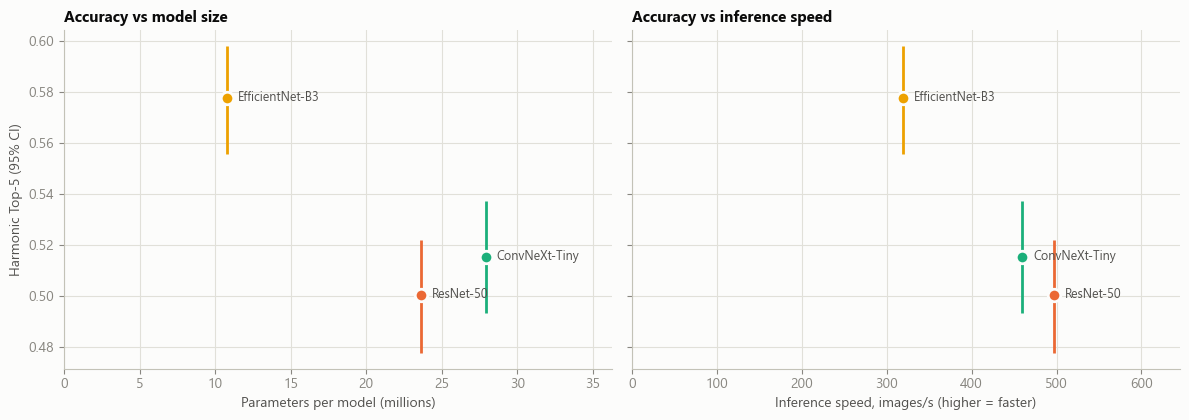

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
xs = [("params per model (M)", "Parameters per model (millions)"),
      ("inference img/s (one model)", "Inference speed, images/s (higher = faster)") if speed else
      ("train time, both models (min)", "Training time, both models (minutes)")]
for ax, (col, xl) in zip(axes, xs):
    for b in present:
        x, y = cost.loc[NAME[b], col], point[FT, b]["harmonic_top5"]
        lo, hi = ci((FT, b), "harmonic_top5")
        ax.vlines(x, lo, hi, color=COLOR[b], linewidth=2)
        ax.plot(x, y, "o", color=COLOR[b], markersize=9, markeredgecolor=SURFACE, markeredgewidth=2)
        ax.annotate(NAME[b], (x, y), xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=INK2)
    ax.set_xlabel(xl); ax.grid(True, axis="both")
    ax.set_xlim(0, cost[col].max() * 1.3)
axes[0].set_ylabel("Harmonic Top-5 (95% CI)")
axes[0].set_title("Accuracy vs model size")
axes[1].set_title("Accuracy vs inference speed" if speed else "Accuracy vs training time")
fig.tight_layout(); plt.show()

## 6. The two independent models on their own

Each model on its own task, before combining. The unseen-test drop is much larger for the **disease** model. Bars are means over seeds; error bars are the SD across seeds.

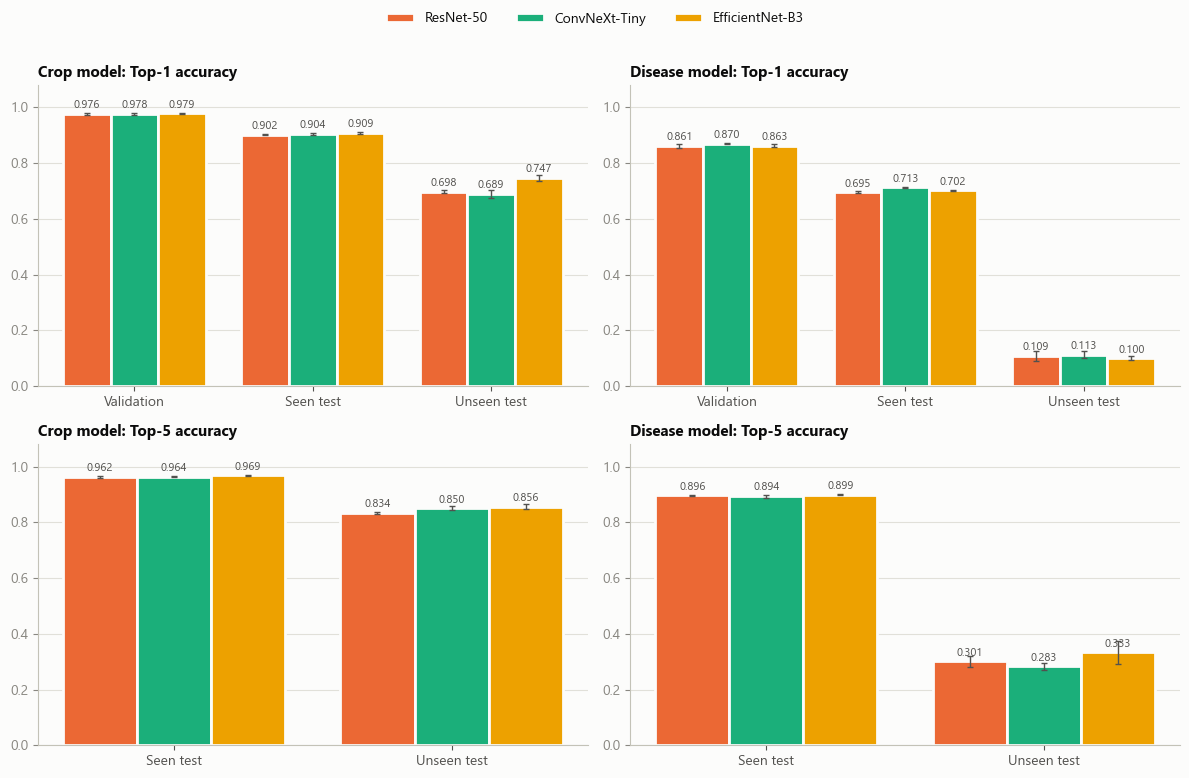

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.8))
for j, task in enumerate(["crop", "disease"]):
    for i, k in enumerate(["top1", "top5"]):
        groups = ["Validation", "Seen test", "Unseen test"] if k == "top1" else ["Seen test", "Unseen test"]
        cols = (["val_top1"] if k == "top1" else []) + [f"seen_{k}", f"unseen_{k}"]
        vals = {b: [tmean(FT, b, task, c) for c in cols] for b in present}
        errs = {b: [tsd(FT, b, task, c) for c in cols] for b in present}
        grouped_bars(axes[i, j], groups, vals, present, errs=errs)
        axes[i, j].set_title(f"{task.capitalize()} model: {'Top-1' if k == 'top1' else 'Top-5'} accuracy")
top_legend(fig, axes[0, 0], top=0.94); plt.show()

## 7. Training curves

Validation Top-1 and training loss per epoch: mean over seeds, band = range across seeds. Each seed's tested
checkpoint is its own best-validation epoch.

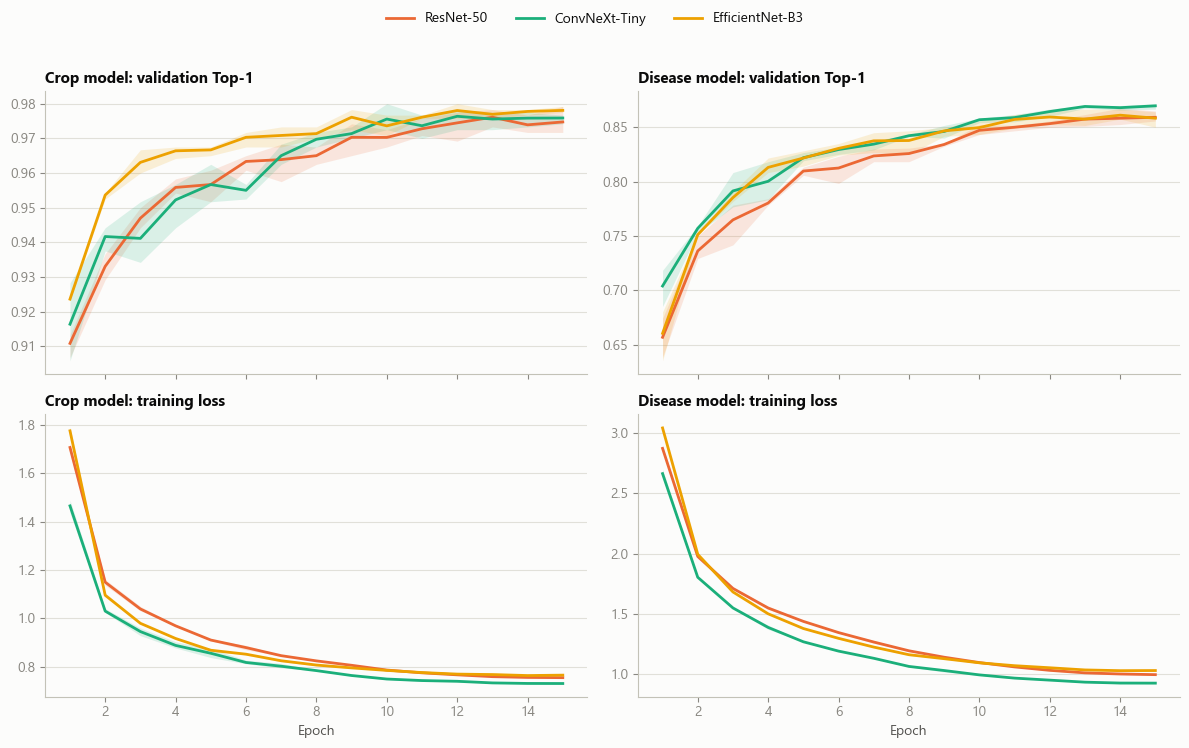

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), sharex=True)
for j, task in enumerate(["crop", "disease"]):
    for b in present:
        hs = [RUN.loc[(FT, b, task, sd), "history"].set_index("epoch") for sd in SEEDS[FT, b]]
        for r, col in enumerate(["val_top1", "train_loss"]):
            v = pd.concat([h[col] for h in hs], axis=1)
            axes[r, j].plot(v.index, v.mean(1), color=COLOR[b], label=NAME[b])
            axes[r, j].fill_between(v.index, v.min(1), v.max(1), color=COLOR[b], alpha=0.15, linewidth=0)
    axes[0, j].set_title(f"{task.capitalize()} model: validation Top-1")
    axes[1, j].set_title(f"{task.capitalize()} model: training loss")
    axes[1, j].set_xlabel("Epoch")
top_legend(fig, axes[0, 0], top=0.93); plt.show()

## 8. Where do composition errors come from?

Each test image's top composition, split by whether its crop and its disease are right. Shares are means over seeds.

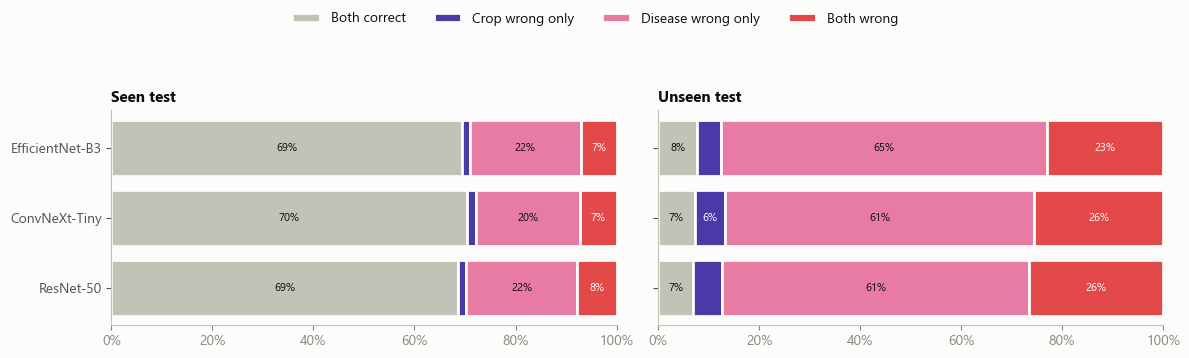

In [14]:
PARTS = [("Both correct", "#c3c2b7"), ("Crop wrong only", "#4a3aa7"),
         ("Disease wrong only", "#e87ba4"), ("Both wrong", "#e34948")]
comp_crop = pd.Series(crop_idx, index=comp_ids); comp_dis = pd.Series(dis_idx, index=comp_ids)

fig, axes = plt.subplots(1, 2, figsize=(12, 0.6 * len(present) + 1.8), sharey=True)
for ax, (split, df) in zip(axes, [("seen", se), ("unseen", un)]):
    for i, b in enumerate(present):
        frs = []
        for sd in SEEDS[FT, b]:
            pred = comp_ids[S[b, sd, split].argmax(1)]
            cok = comp_crop[pred].values == df["crop"].values
            dok = comp_dis[pred].values == df["disease"].values
            frs.append([np.mean(cok & dok), np.mean(~cok & dok), np.mean(cok & ~dok), np.mean(~cok & ~dok)])
        fr = np.mean(frs, 0)
        left = 0
        for (lab, col), f in zip(PARTS, fr):
            ax.barh(i, f, left=left, color=col, edgecolor=SURFACE, linewidth=2, label=lab if i == 0 else None)
            if f >= 0.06:
                ax.text(left + f / 2, i, f"{f:.0%}", ha="center", va="center", fontsize=8,
                        color=INK if col in ("#c3c2b7", "#e87ba4") else "white")
            left += f
    ax.set_yticks(range(len(present)), [NAME[b] for b in present]); ax.invert_yaxis()
    ax.set_xlim(0, 1); ax.grid(False); ax.set_title(f"{split.capitalize()} test"); ax.tick_params(axis="y", colors=INK2)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
top_legend(fig, axes[0], top=0.8); plt.show()

## 9. Per unseen composition

Top-1 accuracy on each of the 10 unseen crop + disease pairs (test images in brackets). Mean over seeds.

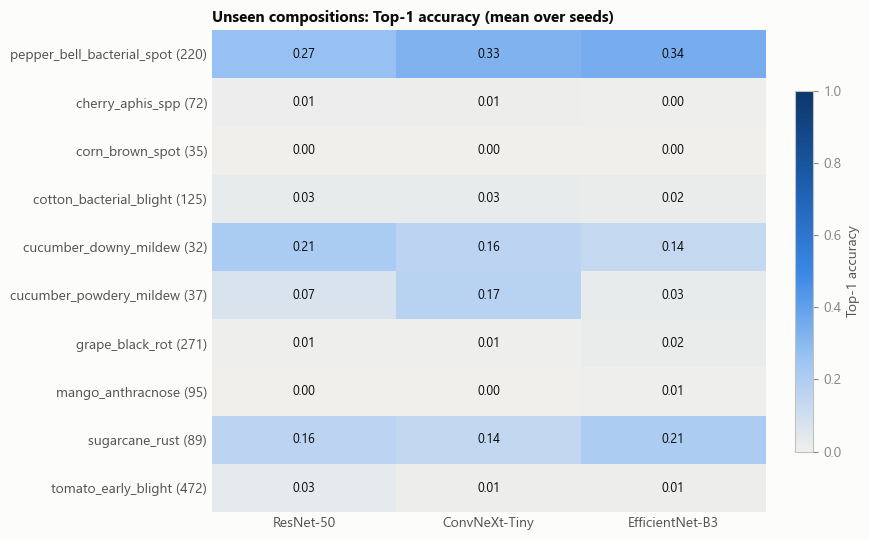

In [15]:
un_comps = sorted(un["comp"].unique())
y_un = un["comp"].values
H = pd.DataFrame({NAME[b]: [np.mean([(comp_ids[S[b, sd, "unseen"].argmax(1)][y_un == c] == c).mean()
                                      for sd in SEEDS[FT, b]]) for c in un_comps]
                  for b in present},
                 index=[f"{comp_name[c]} ({(y_un == c).sum()})" for c in un_comps])

fig, ax = plt.subplots(figsize=(1.6 * len(present) + 4, 5.5))
im = ax.imshow(H.values, cmap=BLUES, vmin=0, vmax=1, aspect="auto")
for (r, c), v in np.ndenumerate(H.values):
    ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=9, color="white" if v > 0.55 else INK)
ax.set_xticks(range(H.shape[1]), H.columns); ax.set_yticks(range(H.shape[0]), H.index)
ax.tick_params(colors=INK2, length=0); ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
fig.colorbar(im, ax=ax, fraction=0.03, label="Top-1 accuracy")
ax.set_title("Unseen compositions: Top-1 accuracy (mean over seeds)")
fig.tight_layout(); plt.show()

## 10. Is the disease model leaning on the crop?

On the unseen test the true disease never appeared on that crop in training. If a disease model has learned
"this crop -> its usual diseases", many of its wrong answers will be diseases that the crop *did* have in training. Rates are means over seeds.

In [16]:
seen_pairs = set(zip(tr["crop"], tr["disease"]))
rows = []
for b in present:
    fr = []
    for sd in SEEDS[FT, b]:
        pred = np.load(RUN.loc[(FT, b, "disease", sd), "dir"] / "probs_unseen.npy").argmax(1)
        right = pred == un["disease"].values
        usual = np.array([(c, p) in seen_pairs for c, p in zip(un["crop"], pred)])
        fr.append([right.mean(), (usual & ~right).mean(), (~usual & ~right).mean()])
    fr = np.mean(fr, 0)
    rows.append({"backbone": NAME[b], "disease correct": fr[0],
                 "wrong: a disease this crop had in training": fr[1], "wrong: other disease": fr[2]})
display(pd.DataFrame(rows).set_index("backbone").round(3))

preds = [np.load(RUN.loc[(FT, BEST, "disease", sd), "dir"] / "probs_unseen.npy").argmax(1) for sd in SEEDS[FT, BEST]]
print(f"{NAME[BEST]}: most frequent disease prediction per unseen composition ({len(preds)} seeds pooled)")
display(pd.DataFrame([{"composition": comp_name[c],
                       "train imgs of the true disease": int((tr["disease"] == un.loc[un["comp"] == c, "disease"].iloc[0]).sum()),
                       "most-predicted disease": dis_name[pd.Series(np.concatenate([p[(un["comp"] == c).values] for p in preds])).mode()[0]]}
                      for c in un_comps]).set_index("composition"))

,disease correct,wrong: a disease this crop had in training,wrong: other disease
backbone,,,
ResNet-50,0.109,0.540,0.352
ConvNeXt-Tiny,0.113,0.543,0.344
EfficientNet-B3,0.100,0.552,0.348


ConvNeXt-Tiny: most frequent disease prediction per unseen composition (3 seeds pooled)


,train imgs of the true disease,most-predicted disease
composition,,
pepper_bell_bacterial_spot,188,bacterial_spot
cherry_aphis_spp,7,erwinia_amylovora
corn_brown_spot,261,lethal_necrosis
cotton_bacterial_blight,147,target_spot
cucumber_downy_mildew,69,anthracnose
cucumber_powdery_mildew,226,powdery_mildew
grape_black_rot,36,esca
mango_anthracnose,51,gall_midge
sugarcane_rust,297,red_rot


## 11. Does class size explain disease errors?

Disease classes are very imbalanced (one has a single training image). Seen-test disease accuracy per backbone,
grouped by how many training images the class has (weighted by test images). Mean over seeds.

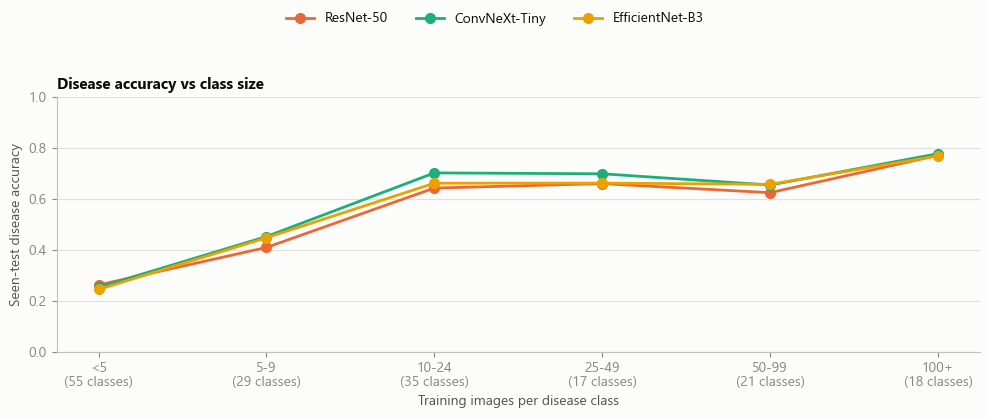

,ResNet-50,ConvNeXt-Tiny,EfficientNet-B3,test images,disease classes
<5,0.262,0.253,0.244,75,55
5-9,0.410,0.452,0.448,70,29
10-24,0.643,0.702,0.662,140,35
25-49,0.660,0.699,0.662,155,17
50-99,0.625,0.655,0.658,365,21
100+,0.772,0.778,0.769,1195,18


In [17]:
bins = [0, 5, 10, 25, 50, 100, 10_000]
labels = ["<5", "5-9", "10-24", "25-49", "50-99", "100+"]
n_train = tr["disease"].value_counts()
cls_bin = pd.cut(se["disease"].map(n_train).fillna(0), bins, right=False, labels=labels)
acc_bin = pd.DataFrame({NAME[b]: pd.concat([pd.Series(np.load(RUN.loc[(FT, b, "disease", sd), "dir"] / "probs_seen.npy").argmax(1)
                                                     == se["disease"].values).groupby(cls_bin.values, observed=False).mean()
                                           for sd in SEEDS[FT, b]], axis=1).mean(1)
                        for b in present})
acc_bin["test images"] = cls_bin.value_counts().reindex(labels).values
acc_bin["disease classes"] = pd.cut(n_train, bins, right=False, labels=labels).value_counts().reindex(labels).values

fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(labels))
for b in present:
    ax.plot(x, acc_bin[NAME[b]], color=COLOR[b], marker="o", markersize=7, label=NAME[b])
ax.set_xticks(x, [f"{l}\n({n} classes)" for l, n in zip(labels, acc_bin["disease classes"])])
ax.set_xlabel("Training images per disease class"); ax.set_ylabel("Seen-test disease accuracy"); ax.set_ylim(0, 1)
ax.set_title("Disease accuracy vs class size")
top_legend(fig, ax, top=0.86); plt.show()
display(acc_bin.round(3))

## 12. Most confused seen compositions and example unseen mistakes (`BEST` backbone)

Confusion counts are summed over seeds; the example images come from one seed.

In [18]:
y_se = se["comp"].values
n_seeds = len(SEEDS[FT, BEST])
wrong = []
for sd in SEEDS[FT, BEST]:
    pred_se = comp_ids[S[BEST, sd, "seen"].argmax(1)]
    wrong.append(pd.DataFrame({"true": comp_name[y_se].values, "predicted": comp_name[pred_se].values})[pred_se != y_se])
wrong = pd.concat(wrong)
print(f"{NAME[BEST]}: {len(wrong) / n_seeds:.0f} of {len(y_se)} seen-test images wrong per seed (mean of {n_seeds} seeds)")
display(wrong.value_counts().rename(f"images, summed over {n_seeds} seeds").head(15).to_frame())

ConvNeXt-Tiny: 591 of 2000 seen-test images wrong per seed (mean of 3 seeds)


,,"images, summed over 3 seeds"
true,predicted,
paddy_healthy,paddy_blast,68
soybean_caterpillar,soybean_diabrotica_speciosa,46
tomato_bacterial_spot,tomato_septoria_leaf_spot,27
paddy_hispa,paddy_blast,27
soybean_healthy,soybean_diabrotica_speciosa,24
tomato_septoria_leaf_spot,tomato_verticulium_wilt,23
soybean_healthy,soybean_caterpillar,22
wheat_stripe_rust,wheat_rust,20
apple_marssonina_blotch,apple_alternaria_leaf_spot,19


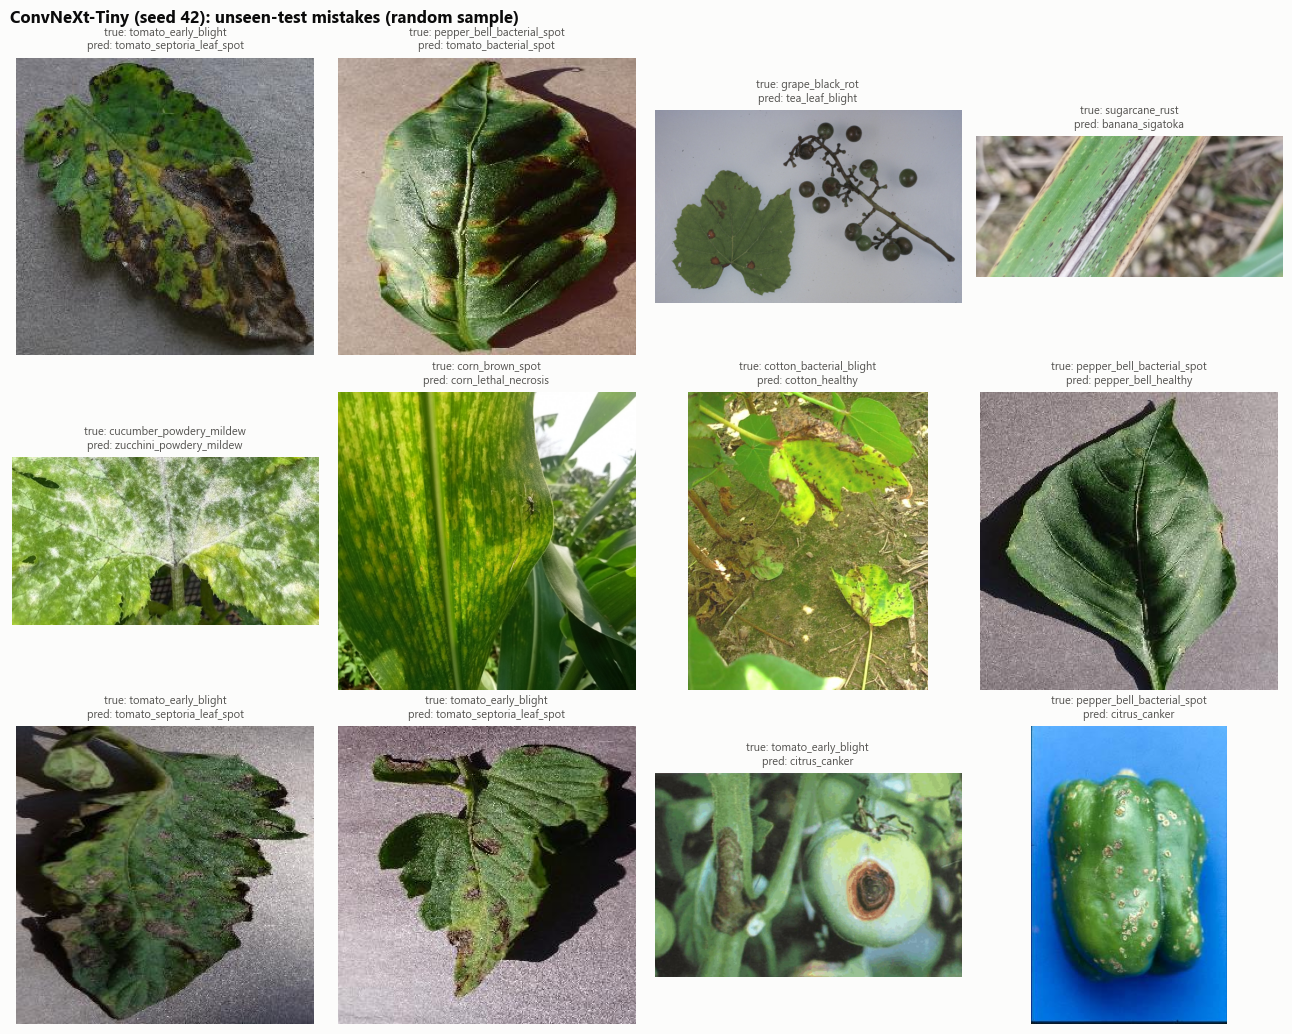

In [19]:
EX_SEED = SEEDS[FT, BEST][0]
pred_un = comp_ids[S[BEST, EX_SEED, "unseen"].argmax(1)]
idx = np.flatnonzero(pred_un != y_un)
pick = np.random.default_rng(0).choice(idx, size=min(12, len(idx)), replace=False)

fig, axes = plt.subplots(3, 4, figsize=(13, 10.5))
for ax in axes.flat:
    ax.axis("off")
for ax, i in zip(axes.flat, pick):
    ax.imshow(Image.open(IMG_DIR / un["file"].iloc[i]).convert("RGB"))
    ax.set_title(f"true: {comp_name[y_un[i]]}\npred: {comp_name[pred_un[i]]}", fontsize=8,
                 fontweight="normal", loc="center", color=INK2)
fig.suptitle(f"{NAME[BEST]} (seed {EX_SEED}): unseen-test mistakes (random sample)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); plt.show()